# Differential geometry and physics with Galileo

This tour shows Galileo's differential geometry: metrics, curvature and geodesics, with 3D graphics, and then uses
the same tools for physics. The highlight is general relativity: why Mercury's orbit slowly turns (the precession of
its perihelion), how light bends around a black hole, and why GPS satellites need Einstein.

Every result below is computed symbolically by Galileo from the metric; the pictures are computed numerically from
those symbolic results. In JupyterLab the 3D graphics are interactive: drag to rotate, scroll to zoom.
As in Matlab, a line ending in `;` is evaluated without showing its result.

**Contents**
1. Metrics and Christoffel symbols
2. Curved surfaces: sphere, torus, saddle and the hyperbolic plane
3. Geodesics: the straightest possible lines
4. General relativity: the Schwarzschild black hole
5. Mercury's perihelion precession
6. Light bending
7. GPS clocks
8. More physics with differential equations

## 1. Metrics and Christoffel symbols

A metric tells you how to measure distances in a coordinate system. `metric(coordinates, components)` defines one;
it is shown as a *line element* $ds^2$. Here is the flat plane in polar coordinates:

In [1]:
p = metric([r phi], [1 0; 0 r^2])

$$ds^2 = \, dr^2 + r^{2}\, d\phi^2$$

The Christoffel symbols $\Gamma^a{}_{bc}$ describe how the coordinate directions turn from point to point. Even in a
flat plane they are not zero in polar coordinates, because the directions $\hat r$ and $\hat\phi$ rotate as you move
around:

In [2]:
christoffel(p)

**Christoffel symbols of the second kind** (coordinates $r$, $\phi$)

$$\begin{aligned}
\Gamma{}^{r}{}_{\phi}{}_{\phi} &= -r \\
\Gamma{}^{\phi}{}_{r}{}_{\phi} &= \frac{1}{r}
\end{aligned}$$

The Gaussian curvature, though, is zero: the plane is flat whichever coordinates you use.

In [3]:
gausscurvature(p)

0.0

## 2. Curved surfaces

`inducedmetric([x y z], [u v])` computes the metric of a surface in space given by $x(u,v)$, $y(u,v)$, $z(u,v)$:
how distances on the surface follow from distances in space (the *first fundamental form*).

### The sphere

In [4]:
sphere = [r*sin(theta)*cos(phi) r*sin(theta)*sin(phi) r*cos(theta)];
g = inducedmetric(sphere, [theta phi])
gausscurvature(g)

$$ds^2 = r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

1.0/r^2.0

A sphere of radius $r$ has the same curvature $1/r^2$ everywhere. Galileo also has it built in, as
`metric.generate(two-sphere)`. Here it is, with radius 1:

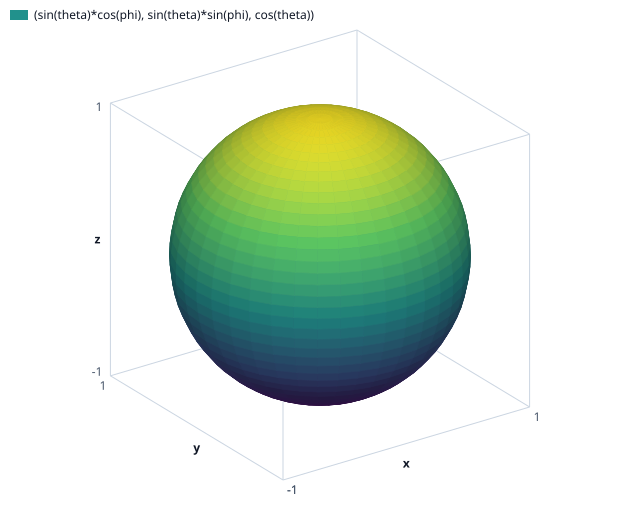

In [5]:
r = 1;
surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi)

### The torus

A doughnut with tube radius $a$ around a circle of radius $R$. Its curvature changes from place to place:

In [6]:
torus = [(R+a*cos(u))*cos(v) (R+a*cos(u))*sin(v) a*sin(u)];
t = inducedmetric(torus, [u v])
K = gausscurvature(t)

$$ds^2 = a^{2}\, du^2 + \left(R + a \cos\left(u\right)\right)^{2}\, dv^2$$

cos(u)/(a*(R+a*cos(u)))

On the outside of the doughnut ($u = 0$) the curvature is positive, like a sphere; on the inside ($u = \pi$) it is
negative, like a saddle. Plotting $K$ around the tube for $R = 2$, $a = 0.7$ shows it changing sign:

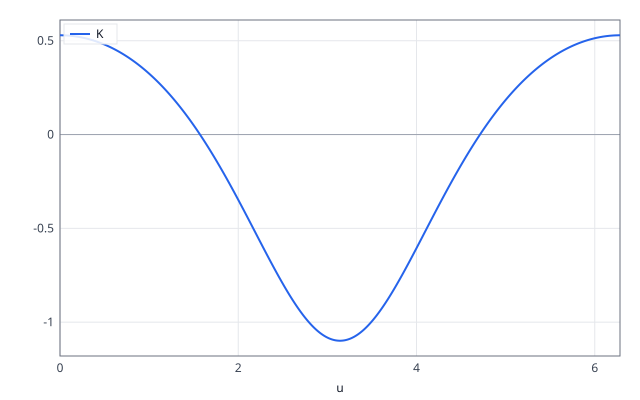

In [7]:
R = 2;
a = 0.7;
plot(K, u, 0, 2*pi)

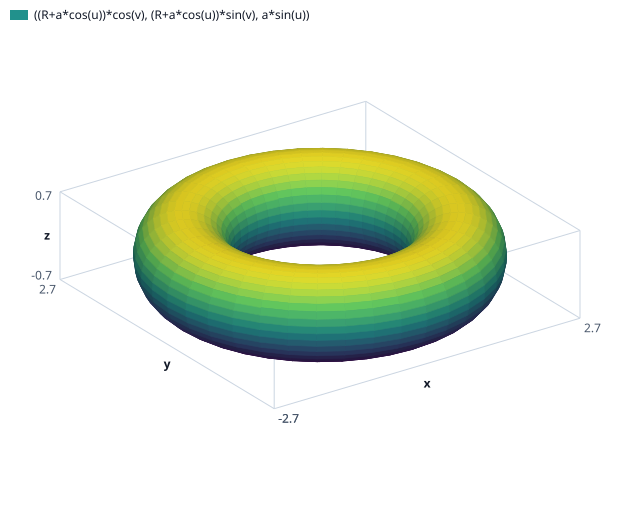

In [8]:
surface((R+a*cos(u))*cos(v), (R+a*cos(u))*sin(v), a*sin(u), u, 0, 2*pi, v, 0, 2*pi)

### The saddle and the hyperbolic plane

The saddle $z = u^2 - v^2$ curves up in one direction and down in the other, so its curvature is negative
everywhere, strongest at the centre:

In [9]:
s = inducedmetric([u v u^2-v^2], [u v])
gausscurvature(s)

$$ds^2 = \left(4 u^{2} + 1\right)\, du^2 - 8 u v\, du\, dv + \left(4 v^{2} + 1\right)\, dv^2$$

(-4.0)/(4.0*u^2.0+4.0*v^2.0+1.0)^2.0

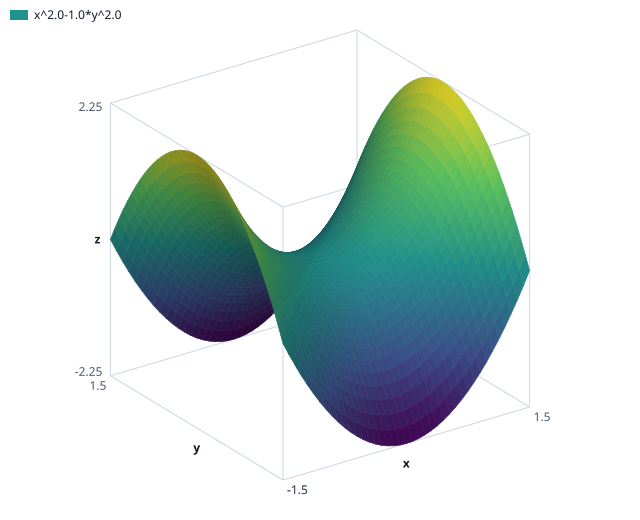

In [10]:
plot3d(x^2-y^2, x, -1.5, 1.5, y, -1.5, 1.5)

The hyperbolic plane has curvature $-1$ everywhere. It cannot be drawn in 3D space without distortion, but its
metric is easy to write down (the upper half plane model):

In [11]:
h = metric.generate(hyperbolic)
gausscurvature(h)

$$ds^2 = \frac{1}{y^{2}}\, dx^2 + \frac{1}{y^{2}}\, dy^2$$

-1.0

## 3. Geodesics

A geodesic is the straightest possible path on a curved surface: what you trace if you walk straight ahead without
turning. `geodesics(g)` gives the equations, $\ddot x^a = -\Gamma^a{}_{bc}\,\dot x^b \dot x^c$:

In [12]:
g = metric.generate(two-sphere)
geodesics(g)

$$ds^2 = r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

**Geodesic equations (' = d/ds along the curve)**

$$\begin{aligned}
\mathrm{theta''} &= \mathrm{phi'}^{2} \cos\left(\theta\right) \sin\left(\theta\right) \\
\mathrm{phi''} &= -\frac{2 \mathrm{phi'} \cos\left(\theta\right) \mathrm{theta'}}{\sin\left(\theta\right)}
\end{aligned}$$

`geodesic(g, start, velocity, length, map)` solves them numerically. Several rows of starting velocities give several
geodesics. The `map` turns coordinates into points in space, here the sphere's embedding. On a sphere every geodesic
is a *great circle*, which is why long-haul flights look curved on flat maps:

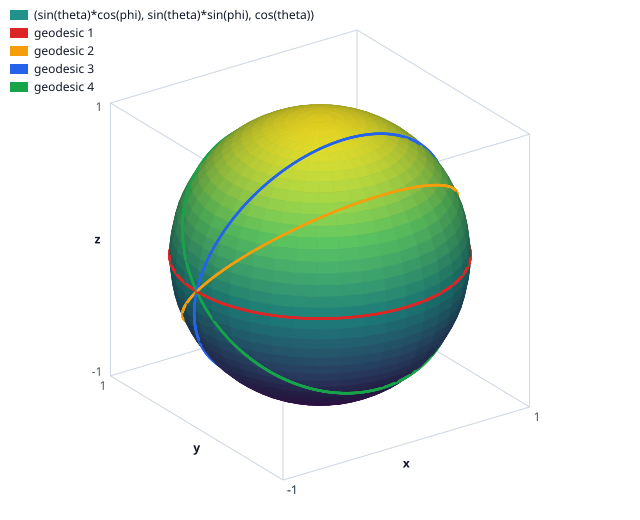

In [13]:
circles = geodesic(g, [pi/2 0], [0 1; 1 1; 1 0.3; 1, -1], 6.3, [sin(theta)*cos(phi) sin(theta)*sin(phi) cos(theta)]);
ball = surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi);
show(ball, circles)

On the torus, geodesics are much more varied. Starting on the outer equator, one goes around the tube, others wind
around the hole, and the one along the equator itself stays there:

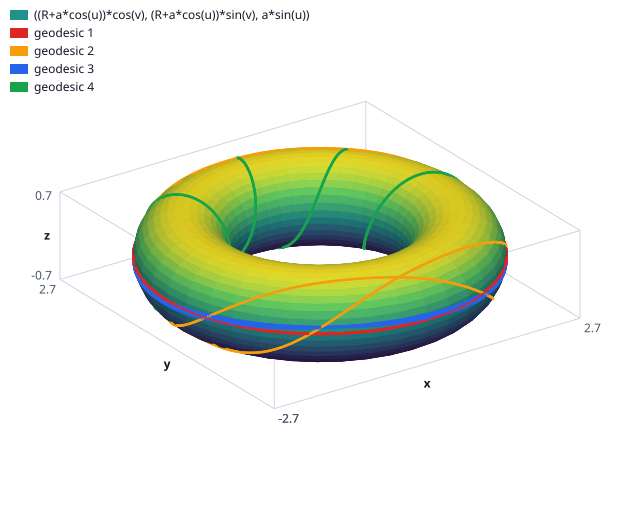

In [14]:
paths = geodesic(t, [0 0], [0 1; 1 0.4; 0.3 1; 1 0.05], 25, torus);
ring = surface((R+a*cos(u))*cos(v), (R+a*cos(u))*sin(v), a*sin(u), u, 0, 2*pi, v, 0, 2*pi);
show(ring, paths)

## 4. General relativity: the Schwarzschild black hole

In general relativity, gravity is the curvature of spacetime, and freely falling objects (planets, light) follow
geodesics of the spacetime metric. Outside a spherical mass $M$ that metric is the *Schwarzschild metric*, with
$r_s = 2GM/c^2$ the Schwarzschild radius:

In [15]:
S = metric.generate(schwarzschild)
christoffel(S)

$$ds^2 = - \frac{r - r_{s}}{r}\, dt^2 + \frac{r}{r - r_{s}}\, dr^2 + r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

**Christoffel symbols of the second kind** (coordinates $t$, $r$, $\theta$, $\phi$)

$$\begin{aligned}
\Gamma{}^{t}{}_{t}{}_{r} &= \frac{r_{s}}{2 r \left(r - r_{s}\right)} \\
\Gamma{}^{r}{}_{t}{}_{t} &= \frac{r_{s} \left(r - r_{s}\right)}{2 r^{3}} \\
\Gamma{}^{r}{}_{r}{}_{r} &= -\frac{r_{s}}{2 r \left(r - r_{s}\right)} \\
\Gamma{}^{r}{}_{\theta}{}_{\theta} &= -r - r_{s} \\
\Gamma{}^{r}{}_{\phi}{}_{\phi} &= -\sin^{2}\left(\theta\right) \left(r - r_{s}\right) \\
\Gamma{}^{\theta}{}_{r}{}_{\theta} &= \frac{1}{r} \\
\Gamma{}^{\theta}{}_{\phi}{}_{\phi} &= -\cos\left(\theta\right) \sin\left(\theta\right) \\
\Gamma{}^{\phi}{}_{r}{}_{\phi} &= \frac{1}{r} \\
\Gamma{}^{\phi}{}_{\theta}{}_{\phi} &= \frac{\cos\left(\theta\right)}{\sin\left(\theta\right)}
\end{aligned}$$

Einstein's equations in empty space say that the Ricci tensor vanishes. Galileo confirms that the Schwarzschild
metric is a vacuum solution:

In [16]:
riccitensor(S)

**Ricci tensor** (coordinates $t$, $r$, $\theta$, $\phi$)

$$\begin{aligned}
R = 0 \quad\text{(all components)}
\end{aligned}$$

The metric looks singular at $r = r_s$ (the event horizon) and at $r = 0$. The *Kretschmann scalar*
$R_{abcd}R^{abcd}$ does not depend on the coordinates, and it shows that only $r = 0$ is a real singularity: the
curvature at the horizon is finite.

In [17]:
kretschmann(S)

12.0*r_s^2.0/r^6.0

### Flamm's paraboloid

A slice of space through the equator (fixed time, $\theta = \pi/2$) has the metric
$dr^2/(1 - r_s/r) + r^2 d\phi^2$. It is exactly the surface $z = 2\sqrt{r_s(r - r_s)}$, the familiar "gravity
well" picture. Galileo checks it:

In [18]:
inducedmetric([r*cos(phi) r*sin(phi) 2*sqrt(r_s*(r-r_s))], [r phi])

$$ds^2 = \frac{r}{r - r_{s}}\, dr^2 + r^{2}\, d\phi^2$$

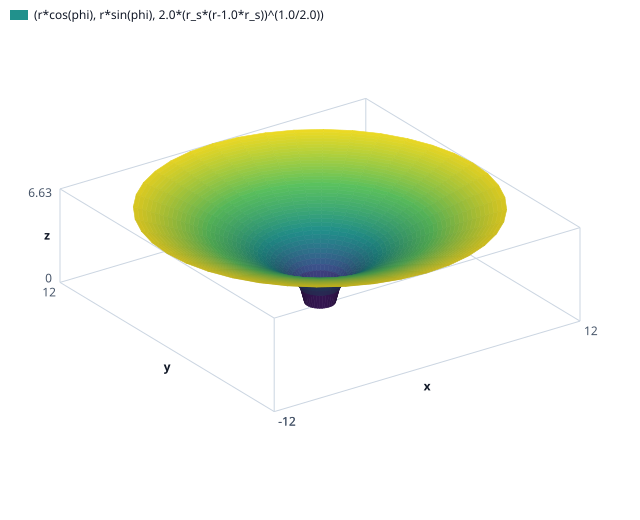

In [19]:
r_s = 1;
surface(r*cos(phi), r*sin(phi), 2*sqrt(r_s*(r-r_s)), r, 1, 12, phi, 0, 2*pi)

## 5. Mercury's perihelion precession

> **A note on "retrograde".** Mercury's *retrograde* motion, when it seems to move backwards across the sky for a
> few weeks, is a line-of-sight effect: Earth overtakes it (or it overtakes Earth) on the inside track. Copernicus
> and Newton explain that fully. What Newton could *not* explain, and Einstein could, is a different effect: the
> slow turning of Mercury's elliptical orbit, called the **precession of the perihelion**. That is what this section
> shows.

Each orbit, Mercury's point of closest approach to the Sun (the perihelion) moves forward a little. Most of that is
caused by the pull of the other planets, but 43 arcseconds per century were left over, and puzzled astronomers for
fifty years. General relativity predicts exactly that amount.

With $u = 1/r$ as a function of the angle $\phi$ and $h$ the angular momentum per unit mass, the orbit equations are
(in units where $c = 1$, so $GM = r_s/2$):

* Newton: $\;u'' + u = \dfrac{GM}{h^2}$, whose solutions are ellipses that close on themselves.
* General relativity (from the Schwarzschild geodesics): $\;u'' + u = \dfrac{GM}{h^2} + 3GM\,u^2$

The extra term is tiny for Mercury, so to *see* it we take an orbit much closer to the mass: perihelion at
$20\,r_s$, aphelion at $60\,r_s$. `odeplot` solves the equations and draws $x = \cos\phi/u$, $y = \sin\phi/u$:

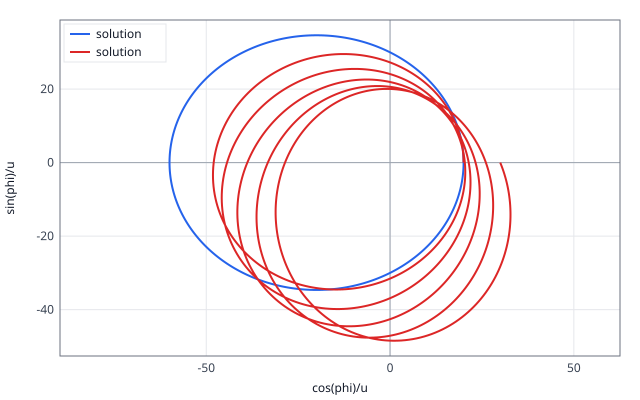

In [20]:
r_s = 1;
h = sqrt(15);
rp = 20;
newton = odeplot([w, r_s/(2*h^2)-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
einstein = odeplot([w, r_s/(2*h^2)+1.5*r_s*u^2-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
show(newton, einstein)

The Newtonian ellipse (first curve) retraces itself; the relativistic orbit (second curve) turns a little further
each time, tracing a rosette. The predicted shift per orbit is
$\Delta\phi = \dfrac{6\pi GM}{c^2\, a (1 - e^2)} = \dfrac{3\pi r_s}{p}$, where $p = h^2/GM$ is the orbit's semi-latus
rectum. Here $p = 30\,r_s$:

In [21]:
p = 2*h^2/r_s
eval(3*pi*r_s/p*180/pi)

30.0
18.0

About 18° per orbit, which matches the picture. The orbit equation above came from the geodesics; as an independent
check, `geodesic` can integrate the full four-dimensional geodesic equations of the Schwarzschild metric directly.
The planet starts at perihelion with angular velocity $L/r^2$ and the time component $\dot t$ fixed so that
$g_{ab}\dot x^a \dot x^b = -1$:

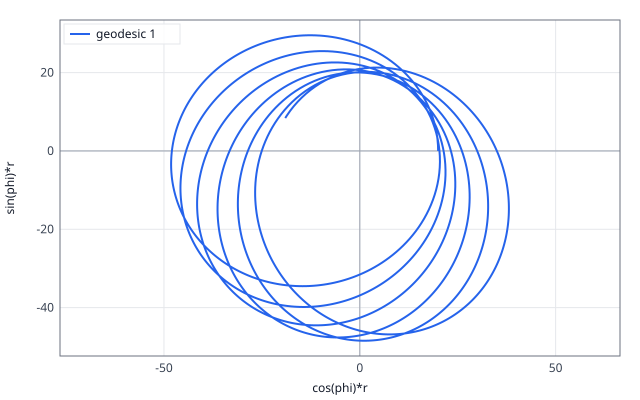

In [22]:
L = h;
ut = sqrt((1+L^2/rp^2)/(1-r_s/rp));
geodesic(S, [0 rp pi/2 0], [ut 0 0 L/rp^2], 11000, [r*cos(phi) r*sin(phi)], 20000)

The same rosette, straight from the metric.

### Mercury's numbers

Now the real thing, in SI units: the Sun's $GM$, the speed of light, and Mercury's semi-major axis, eccentricity and
orbital period (in days).

In [23]:
GM = 1.32712440018e20;
c = 299792458;
A = 5.7909e10;
ecc = 0.2056;
T = 87.969;
dphi = eval(6*pi*GM/(c^2*A*(1-ecc^2)))

5.018602644417365E-7

That is the shift per orbit in radians. Mercury goes around $36525/T$ times per century; converting to arcseconds:

In [24]:
eval(dphi*(36525/T)*(180/pi)*3600)

42.98020808869248

**43 arcseconds per century**, the anomaly that Einstein explained in 1915.

## 6. Light bending

Light also follows geodesics, *null* ones with $g_{ab}\dot x^a \dot x^b = 0$. Here a flash of light goes off at
$r = 3\,r_s$, sending rays in many directions. Each row of the velocity matrix is one ray, leaving at angle $A$
from the outward direction: $(\dot t, \dot r, \dot\theta, \dot\phi) = (1/k,\; k\cos A,\; 0,\; \sin A / r_0)$ with
$k = \sqrt{1 - r_s/r_0}$.

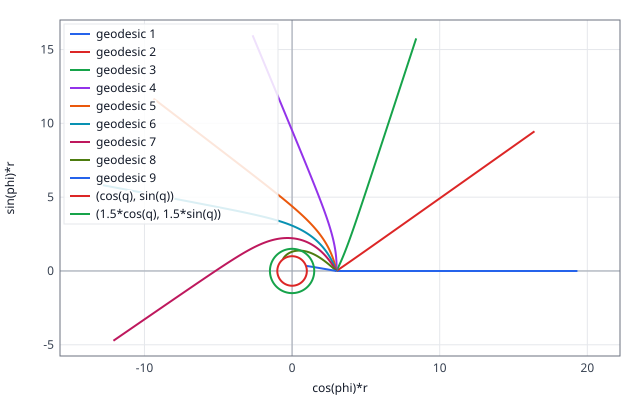

In [25]:
r0 = 3;
k = sqrt(1-r_s/r0);
ut = 1/k;
rays = geodesic(S, [0 r0 pi/2 0], [ut, k, 0, 0; ut, k*cos(0.5), 0, sin(0.5)/r0; ut, k*cos(1), 0, sin(1)/r0; ut, k*cos(1.5), 0, sin(1.5)/r0; ut, k*cos(1.8), 0, sin(1.8)/r0; ut, k*cos(2.0), 0, sin(2.0)/r0; ut, k*cos(2.2), 0, sin(2.2)/r0; ut, k*cos(2.5), 0, sin(2.5)/r0; ut, k*cos(3), 0, sin(3)/r0], 20, [r*cos(phi) r*sin(phi)]);
horizon = parametric(cos(q), sin(q), q, 0, 2*pi);
photonsphere = parametric(1.5*cos(q), 1.5*sin(q), q, 0, 2*pi);
show(rays, horizon, photonsphere)

Rays aimed outwards escape, bent by gravity; rays aimed inwards cross the horizon (the unit circle) and never come
back. Near the *photon sphere* at $r = 1.5\,r_s$, light can circle the black hole.

For a light ray grazing the Sun, the deflection is $4GM/(c^2 R_\odot)$. In arcseconds:

In [26]:
Rsun = 6.957e8;
eval(4*GM/(c^2*Rsun)*(180/pi)*3600)

1.7511903257975012

1.75 arcseconds, twice what a Newtonian argument gives. Eddington's eclipse expedition measured it in 1919 and made
Einstein famous.

## 7. GPS clocks

The time component of the Schwarzschild metric, $g_{tt} = -(1 - r_s/r)$, says that clocks deeper in a gravitational
field run slower. GPS satellites orbit at 26 561 km from Earth's centre. Their clocks run *faster* than clocks on the
ground because of the weaker gravity, and *slower* because of their speed (special relativity). In microseconds per
day:

In [27]:
GMe = 3.986004418e14;
Re = 6.371e6;
rgps = 2.6561e7;
day = 86400;
gravity = eval(GMe/c^2*(1/Re-1/rgps)*day*1e6)
speed = eval(-GMe/(2*rgps*c^2)*day*1e6)
eval(gravity+speed)

45.71875595513805
-7.213328236507789
38.50542771863026

About 38 microseconds per day. Light travels 11 km in that time, so without the correction GPS positions would drift
by kilometres every day.

## 8. More physics with differential equations

`odeplot` solves any system $\dot y = f(t, y)$. Use commas between elements that start with a minus sign.

### The pendulum

The phase portrait of a pendulum, $\ddot x = -\sin x$: small swings are ellipses, large ones are distorted, and
above the *separatrix* the pendulum goes over the top (the curves along the top and bottom).

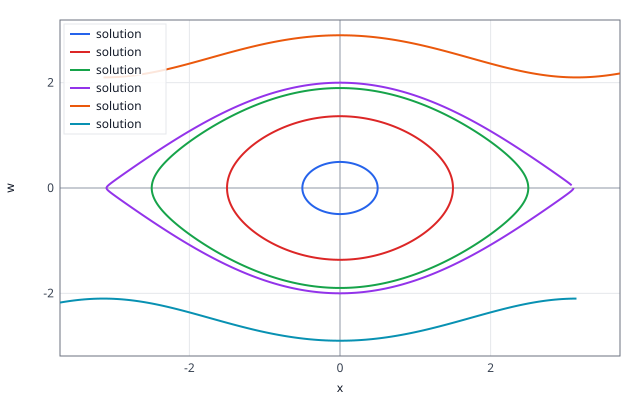

In [28]:
p1 = odeplot([w, -sin(x)], [x w], t, [0.5 0], 0, 10, [x w]);
p2 = odeplot([w, -sin(x)], [x w], t, [1.5 0], 0, 10, [x w]);
p3 = odeplot([w, -sin(x)], [x w], t, [2.5 0], 0, 12, [x w]);
p4 = odeplot([w, -sin(x)], [x w], t, [3.1 0], 0, 20, [x w]);
p5 = odeplot([w, -sin(x)], [x w], t, [-3.14 2.1], 0, 2.8, [x w]);
p6 = odeplot([w, -sin(x)], [x w], t, [3.14, -2.1], 0, 2.8, [x w]);
show(p1, p2, p3, p4, p5, p6)

### The Lorenz attractor

Lorenz's 1963 model of convection in the atmosphere, the classic example of chaos. The solution never repeats and
never settles down, but stays on a butterfly-shaped set:

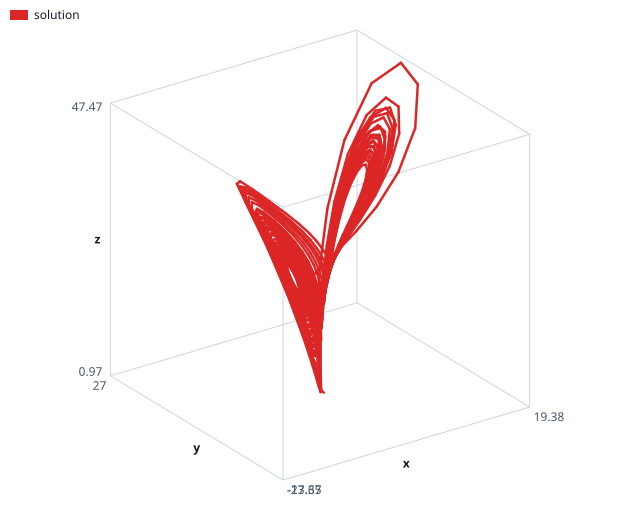

In [29]:
sigma = 10;
rho = 28;
beta = 8/3;
odeplot([sigma*(y-x) x*(rho-z)-y x*y-beta*z], [x y z], t, [1 1 1], 0, 40, [x y z])

## Where to go next

* `riemannsecond(g)`, `einsteintensor(g)`, `weyltensor(g)` and `ricciscalar(g)` work for any metric.
* Ready-made metrics: `minkowski`, `euclidean`, `polar`, `spherical`, `two-sphere`, `three-sphere`, `torus`,
  `hyperbolic`, `schwarzschild` (use `metric.generate(name)`).
* The [Galileo language reference](https://github.com/cascala/galileo/blob/master/docs/language.md) lists every
  command.